# 实验03：逻辑回归与大学排名分类
主讲：胡泷；整理：胡泷、曾有成；任课教师：钟志诚；中国科学技术大学 人工智能与数据科学学院。

QS（Quacquarelli Symonds）2026：根据部分同年已公布信息识别前500名。不是未来排名预测。按C0–C7在student.py中补全。数值及类别状态只拟合训练集。完整报告按上一级report-template.md组织。

**使用步骤：**每次打开 Notebook 或重启内核后，先运行下面的初始化单元格。之后修改 `student.py`，按 **Ctrl+S 保存**，再运行对应检查点；Notebook 会自动加载保存后的代码，无需每次重启内核。初始化会显示正在使用的文件路径，请编辑该文件。

**修改前面阶段后：**已有的训练数据、DataLoader、模型和结果不会自动重新计算。请从修改的阶段开始，按顺序重新运行后续已完成的单元格。若提示变量未定义，请先运行初始化和所依赖的前序单元格。若提示“先完成 C…”，请检查对应函数是否已保存、是否仍返回 `None`。

In [2]:
%load_ext autoreload
%autoreload 1
%aimport student
from pathlib import Path
import pandas as pd
import torch
import support
import checkpoints
import workflow
torch.set_num_threads(1)
output = Path("outputs-qs-notebook")
print("自动加载已启用。请编辑并保存：", Path(student.__file__).resolve())

自动加载已启用。请编辑并保存： D:\ai\ustc-ai-math-experiments-26fall-b\实验03_逻辑回归与大学排名分类\code\student.py


## C0：先观察形状
运行已提供例子，修改一个权重并先预测结果。

In [2]:
checkpoints.check(student, 0)

课堂训练表形状： (902, 11) 缺失标签： 0
X @ w = [[2.0], [-1.0]]
C0 PASS


## C1：标签和数值清洗
补filter_labels、clean_numeric；记录缺失与输入白名单。

In [6]:
frame = support.load_split(support.DATA_DIR, "train")
print(frame.shape)
print(frame.isna().sum())
print(frame["top500"].value_counts())
checkpoints.check(student, 1)

(902, 11)
row_id                          0
name                            0
region                          0
status                         31
size                            0
focus                           0
research                        0
faculty_student_score           0
international_faculty_score    49
international_student_score    18
top500                          0
dtype: int64
top500
0    601
1    301
Name: count, dtype: int64
C1 PASS


## C2：数值标准化与独热编码
补五个函数；解释Unknown、列对齐和常数列。独热列保留0/1。

In [11]:
checkpoints.check(student, 2)
train, val, state = support.prepare_train_val(student, support.DATA_DIR)
print(train[0].shape, train[1].shape)
print(val[0].shape, val[1].shape)
print(state["means"])
print(state["categories"])

C2 PASS
torch.Size([902, 29]) torch.Size([902, 1])
torch.Size([300, 29]) torch.Size([300, 1])
faculty_student_score          33.201330
international_faculty_score    35.671630
international_student_score    32.886312
dtype: float64
{'region': ['Africa', 'Americas', 'Asia', 'Europe', 'Oceania', 'Unknown'], 'status': ['Private for Profit', 'Private not for Profit', 'Public', 'Unknown'], 'size': ['L', 'M', 'S', 'XL', 'Unknown'], 'focus': ['CO', 'FC', 'FO', 'SP', 'Unknown'], 'research': ['HI', 'LO', 'MD', 'VH', 'Unknown']}


## C3：成对批次
补UniversityDataset与make_loader，观察15批和末批6条。

In [12]:
checkpoints.check(student, 3)
loader = student.make_loader(student.UniversityDataset(*train), 64, False)
print([len(y) for X, y in loader])

C3 PASS
[64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 64, 6]


## C4：得分与概率
补参数注册、forward、sigmoid，说明三个输出：得分、概率、类别。

In [13]:
checkpoints.check(student, 4)
model = student.LogisticRegression(train[0].shape[1])
print(model(train[0][:3]))
print(student.sigmoid(model(train[0][:3])))

C4 PASS
tensor([[0.],
        [0.],
        [0.]], grad_fn=<MmBackward0>)
tensor([[0.5000],
        [0.5000],
        [0.5000]], grad_fn=<MulBackward0>)


## C5：损失与正则化
补data_loss与penalty；核对截距不受罚。

In [14]:
checkpoints.check(student, 5)

C5 PASS


## C6：一次更新
补train_epoch；在报告中保留手算，不只记录PASS。

In [16]:
checkpoints.check(student, 6)

C6 PASS


## C7：验证选模
补binary_metrics。固定三种正则设置，用验证数据损失选择；尚不读取测试。

In [17]:
checkpoints.check(student, 7)
workflow.train_candidates(student, support.DATA_DIR, output)
display(pd.read_csv(output / "candidates.csv"))
display(pd.read_csv(output / "validation_thresholds.csv"))

C7 PASS
{'kind': 'none', 'strength': 0.0, 'lr': 0.05, 'epoch': 60, 'max_epochs': 60, 'batch_size': 64, 'seed': 42, 'val_loss': 0.37179243564605713, 'val_accuracy': 0.83, 'val_precision': 0.7752808988764045, 'val_recall': 0.69, 'val_f1': 0.7301587301587302}
{'kind': 'l2', 'strength': 0.01, 'lr': 0.05, 'epoch': 60, 'max_epochs': 60, 'batch_size': 64, 'seed': 42, 'val_loss': 0.3795522451400757, 'val_accuracy': 0.83, 'val_precision': 0.7816091954022989, 'val_recall': 0.68, 'val_f1': 0.7272727272727274}
{'kind': 'l1', 'strength': 0.01, 'lr': 0.05, 'epoch': 60, 'max_epochs': 60, 'batch_size': 64, 'seed': 42, 'val_loss': 0.3927444517612457, 'val_accuracy': 0.83, 'val_precision': 0.7816091954022989, 'val_recall': 0.68, 'val_f1': 0.7272727272727274}
主实验模型、特征和阈值已冻结；未读取测试集。


,kind,strength,lr,epoch,max_epochs,batch_size,seed,val_loss,val_accuracy,val_precision,val_recall,val_f1
0,none,0.00,0.05,60,60,64,42,0.371792,0.83,0.775281,0.69,0.730159
1,l2,0.01,0.05,60,60,64,42,0.379552,0.83,0.781609,0.68,0.727273
2,l1,0.01,0.05,60,60,64,42,0.392744,0.83,0.781609,0.68,0.727273


,threshold,tn,fp,fn,tp,accuracy,precision,recall,f1
0,0.3,163,37,18,82,0.816667,0.689076,0.82,0.748858
1,0.5,180,20,31,69,0.830000,0.775281,0.69,0.730159
2,0.7,197,3,44,56,0.843333,0.949153,0.56,0.704403


### 选做：完整与精简特征
删除focus和research，固定L2=0.01，比较验证表现；不覆盖主实验选择。

In [18]:
RUN_FEATURE_STUDY = False
if RUN_FEATURE_STUDY:
    workflow.feature_study(student, support.DATA_DIR, output)
    display(pd.read_csv(output / "feature_study/comparison.csv"))

### 冻结方案与曲线
先记录所选方案和阈值；每条曲线均是不含正则的数据损失。

{'kind': 'none', 'strength': 0.0, 'lr': 0.05, 'epoch': 60, 'max_epochs': 60, 'batch_size': 64, 'seed': 42, 'val_loss': 0.37179243564605713, 'val_accuracy': 0.83, 'val_precision': 0.7752808988764045, 'val_recall': 0.69, 'val_f1': 0.7301587301587302, 'threshold': 0.5, 'feature_set': 'full', 'input_dim': 29, 'train_n': 902, 'val_n': 300, 'train_positive_fraction': 0.3337028920650482, 'majority_class': 0, 'python': '3.11.16', 'torch': '2.14.0+cpu', 'pandas': '3.0.5'}


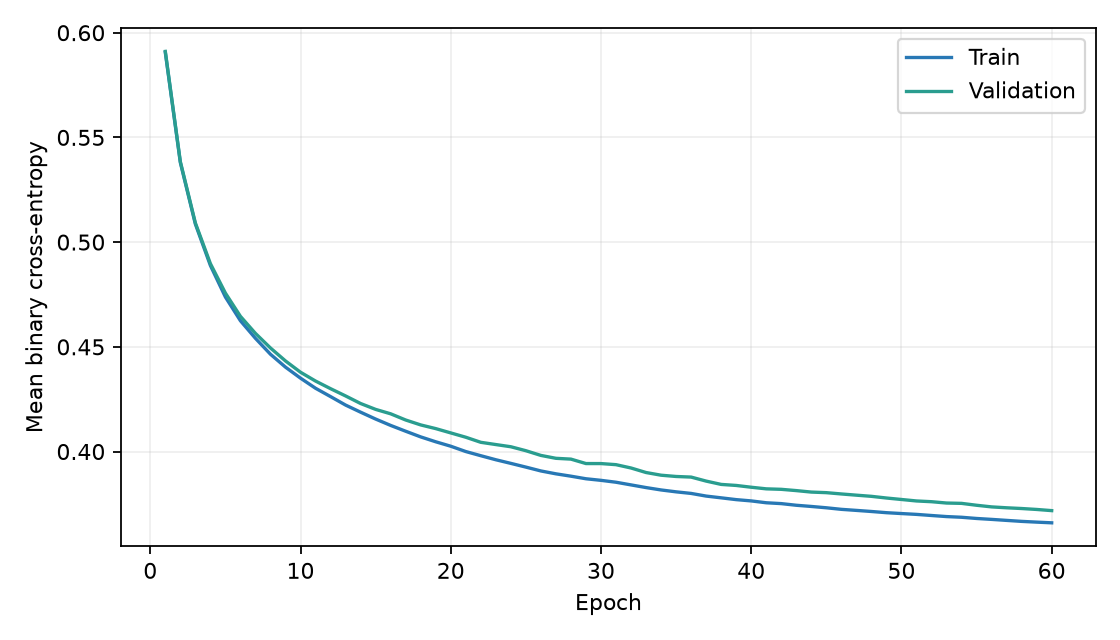

In [19]:
import json
from IPython.display import Image, display
selected = json.loads((output / "selection.json").read_text())
print(selected)
display(Image(filename=str(output / (selected["kind"] + "_loss.png"))))

### 最终测试
记录主实验方案后，将开关改为True，执行一次。不根据测试结果回调参数、特征或阈值。

In [21]:
RUN_FINAL_TEST = True
if RUN_FINAL_TEST:
    workflow.final_test(student, support.DATA_DIR, output)
else:
    print("尚未执行测试，请先记录冻结方案。")

{
  "tn": 185,
  "fp": 16,
  "fn": 32,
  "tp": 69,
  "accuracy": 0.8410596026490066,
  "precision": 0.8117647058823529,
  "recall": 0.6831683168316832,
  "f1": 0.7419354838709677,
  "loss": 0.37160637974739075,
  "majority_baseline_accuracy": 0.6655629139072847,
  "test_n": 302,
  "threshold": 0.5
}
测试完成，不根据此结果重选参数、特征或阈值。


## 报告与反馈
按模板记录各检查点实现、小例子和解释；综合结果放一张曲线和一张混淆矩阵。总结正则化、阈值、选做特征选择的实际作用，并说明同年分类的局限。